# 11. Shot data (2021-22 to 2025-26)

Shot-level data from MoneyPuck feeds two later features: a shot heat map on the card, and clutch via win probability added (WPA). This notebook only loads it:

1. reads the CSV straight from `data/shots_raw/shots_2021-2025.zip` (nothing is unzipped to disk)
2. keeps 30 of the 124 columns, in compact types
3. drops playoff games and saves `data/shots_2021-2025.parquet` (gitignored)
4. checks goals against the skater files, every game's winner and running score, and the shot coordinates

`season` is MoneyPuck's start year (2025 = 2025-26), the same as the rest of the project. A game is identified by `(season, game_id)`, because game IDs repeat across seasons.

The data has no assister columns. Overtime and shootout aren't columns either; step 5 works them out from the goals.

Data: MoneyPuck.com. Raw data stays in `data/` and is never published.

## 1. Setup

In [1]:
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from player_card import season_label

DATA = Path("../data")
ZIP_PATH = DATA / "shots_raw" / "shots_2021-2025.zip"
CSV_NAME = "shots_2021-2025.csv"
DICT_PATH = DATA / "shots_raw" / "MoneyPuck_Shot_Data_Dictionary.csv"
OUT_PATH = DATA / "shots_2021-2025.parquet"
SEASONS = [2021, 2022, 2023, 2024, 2025]   # MoneyPuck start years: 2025 = 2025-26
GAME = ["season", "game_id"]               # game IDs repeat across seasons

# Columns kept, with compact types
KEEP = {
    # keys
    "shotID": "int32", "season": "int16", "game_id": "int32", "isPlayoffGame": "int8",
    "id": "int16",                          # event number in the game: orders events within the same second
    # game state (WPA)
    "period": "int8", "time": "int16",      # time = seconds into the game; period 4 = overtime
    "homeTeamCode": "category", "awayTeamCode": "category", "isHomeTeam": "int8", "homeTeamWon": "int8",
    "homeTeamGoals": "int8", "awayTeamGoals": "int8",          # score BEFORE the shot
    "homeSkatersOnIce": "int8", "awaySkatersOnIce": "int8",
    "homeEmptyNet": "int8", "awayEmptyNet": "int8", "shotOnEmptyNet": "int8",
    # the shot (heat map)
    "event": "category", "goal": "int8", "xGoal": "float32",
    "arenaAdjustedXCord": "float32", "arenaAdjustedYCord": "float32",   # sign of x = rink end; fold in step 6
    "xCordAdjusted": "float32", "yCordAdjusted": "float32",             # MoneyPuck's one-end coordinates (no arena fix)
    "arenaAdjustedShotDistance": "float32",
    # shooter (checks)
    "shooterPlayerId": "Int32", "shooterName": "category", "playerPositionThatDidEvent": "category",
    "teamCode": "category",
}

# Every kept column must exist in both the zip and the data dictionary
dictionary = pd.read_csv(DICT_PATH)
with zipfile.ZipFile(ZIP_PATH) as z, z.open(CSV_NAME) as f:
    header = f.readline().decode().strip().split(",")
missing_header = [c for c in KEEP if c not in header]
missing_dict = [c for c in KEEP if c not in set(dictionary["Variable"])]
assert not missing_header, f"Not in the zip: {missing_header}"
assert not missing_dict, f"Not in the data dictionary: {missing_dict}"
print(f"Keeping {len(KEEP)} of {len(header)} columns")

Keeping 30 of 124 columns


## 2. Load from the zip

Read only the kept columns, then convert them to compact types. Some whole numbers are stored as "1.0" in the CSV, so they are converted after reading, not during.

In [2]:
with zipfile.ZipFile(ZIP_PATH) as z, z.open(CSV_NAME) as f:
    shots_all = pd.read_csv(f, usecols=list(KEEP))
shots_all = shots_all[list(KEEP)].astype(KEEP)
print(f"Rows in the zip: {len(shots_all):,} (MoneyPuck lists 605,110)\n")

kind = shots_all["isPlayoffGame"].map({0: "regular season", 1: "playoffs"})
by_season = pd.crosstab(shots_all["season"].map(season_label), kind, margins=True, margins_name="total")
print(by_season.to_string())

Rows in the zip: 605,110 (MoneyPuck lists 605,110)

isPlayoffGame  playoffs  regular season   total
season                                         
2021-22            8313          113158  121471
2022-23            7972          114054  122026
2023-24            7689          114783  122472
2024-25            7718          112152  119870
2025-26            7260          112011  119271
total             38952          566158  605110


## 3. Drop playoffs and save as Parquet

In [3]:
shots = shots_all[shots_all["isPlayoffGame"] == 0].reset_index(drop=True)
assert shots["isPlayoffGame"].eq(0).all()
print(f"Regular-season shots: {len(shots):,}")

no_shooter = shots["shooterPlayerId"].isna() | shots["shooterPlayerId"].eq(0)
print(f"Shots with no shooter ID (missing or 0): {int(no_shooter.sum())}, of which goals: {int(shots.loc[no_shooter, 'goal'].sum())}")

shots.to_parquet(OUT_PATH, engine="pyarrow", index=False)
back = pd.read_parquet(OUT_PATH)
assert back.shape == shots.shape, "Parquet file does not read back with the same shape"
print(f"\nSaved data/{OUT_PATH.name}: {OUT_PATH.stat().st_size / 1e6:.1f} MB "
      f"({len(back):,} rows, {back.shape[1]} columns; the raw CSV is 361 MB)")

Regular-season shots: 566,158
Shots with no shooter ID (missing or 0): 24, of which goals: 1

Saved data/shots_2021-2025.parquet: 12.9 MB (566,158 rows, 30 columns; the raw CSV is 361 MB)


## 4. Check: goals per player-season vs. the skater files

Goals counted from the shot data, compared with `I_F_goals` (all situations) in `data/skaters<label>.csv`, the files the WAR model uses. This reports and does not stop the notebook: small gaps can be legitimate.

In [4]:
scored = shots[(shots["goal"] == 1) & shots["shooterPlayerId"].notna()]
from_shots = (scored.groupby(["season", "shooterPlayerId"]).size().rename("shot_data_goals").reset_index()
                    .rename(columns={"shooterPlayerId": "playerId"}))
from_shots["season"] = from_shots["season"].astype("int64")
from_shots["playerId"] = from_shots["playerId"].astype("int64")

skaters = []
for s in SEASONS:
    raw = pd.read_csv(DATA / f"skaters{season_label(s)[2:]}.csv", usecols=["playerId", "season", "name", "situation", "I_F_goals"])
    skaters.append(raw[raw["situation"] == "all"])
skaters = (pd.concat(skaters)[["season", "playerId", "name", "I_F_goals"]]
             .rename(columns={"I_F_goals": "skater_file_goals"}))

check = from_shots.merge(skaters, on=["season", "playerId"], how="outer", indicator=True)
check[["shot_data_goals", "skater_file_goals"]] = check[["shot_data_goals", "skater_file_goals"]].fillna(0).astype(int)
shot_names = (scored.drop_duplicates("shooterPlayerId").assign(pid=lambda d: d["shooterPlayerId"].astype("int64"))
                    .set_index("pid")["shooterName"].astype(str))
check["name"] = check["name"].fillna(check["playerId"].map(shot_names))
check["diff"] = check["shot_data_goals"] - check["skater_file_goals"]

match = check["diff"].eq(0)
scorers = check[(check["shot_data_goals"] > 0) | (check["skater_file_goals"] > 0)]
print(f"Goals: {check['shot_data_goals'].sum():,} in the shot data, {check['skater_file_goals'].sum():,} in the skater files")
print(f"Player-seasons that match exactly: {match.sum():,} of {len(check):,} ({match.mean():.1%})")
print(f"Among player-seasons with at least 1 goal: {scorers['diff'].eq(0).sum():,} of {len(scorers):,} ({scorers['diff'].eq(0).mean():.1%})")
print(f"Player-seasons with goals in the shot data but not in the skater files: {int((check['_merge'] == 'left_only').sum())}")

print("\n10 biggest mismatches")
worst = check.reindex(check["diff"].abs().sort_values(ascending=False).index).head(10)
worst = worst.assign(season=worst["season"].map(season_label))
print(worst[["name", "season", "shot_data_goals", "skater_file_goals", "diff"]].to_string(index=False))

Goals: 40,411 in the shot data, 40,464 in the skater files
Player-seasons that match exactly: 4,625 of 4,743 (97.5%)
Among player-seasons with at least 1 goal: 3,656 of 3,774 (96.9%)
Player-seasons with goals in the shot data but not in the skater files: 5

10 biggest mismatches
             name  season  shot_data_goals  skater_file_goals  diff
       Tim Sttzle 2022-23               37                 39    -2
     Jeff Skinner 2021-22               31                 33    -2
Michael Rasmussen 2024-25                9                 11    -2
   David Pastrnak 2023-24               45                 47    -2
   Tyson Foerster 2023-24               18                 20    -2
      Nick Suzuki 2022-23               25                 26    -1
Aleksander Barkov 2023-24               22                 23    -1
  Jonathan Drouin 2021-22                5                  6    -1
      Kyle Connor 2022-23               32                 31     1
   William Eklund 2022-23               

## 5. Check: every game's winner and running score

For WPA, every game needs a known winner, and the score has to be trackable shot by shot. Each game is labeled from its goals:
- **REG**: regulation (periods 1 to 3) not tied
- **OT**: tied after regulation, decided by an overtime goal
- **SO**: still tied after all goals, so decided by a shootout (shootout attempts aren't in the data, so the winner can't be rebuilt; these are counted, not flagged)

In [5]:
games = shots.groupby(GAME, observed=True).agg(
    home=("homeTeamCode", "first"), away=("awayTeamCode", "first"),
    won_values=("homeTeamWon", "nunique"), home_won=("homeTeamWon", "first"))

print("Games per season (a full 32-team season is 1,312)")
print(games.groupby(level="season").size().rename(index=season_label).to_string())
print(f"\nEvery game has exactly one homeTeamWon value: {bool(games['won_values'].eq(1).all())}")

goal_rows = shots[shots["goal"] == 1]

def goals_by_side(rows):
    """Home and away goals per game (0 if none)."""
    counts = rows.groupby(GAME + ["isHomeTeam"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=[0, 1], fill_value=0).reindex(games.index, fill_value=0)
    return counts[1], counts[0]

games["home_goals"], games["away_goals"] = goals_by_side(goal_rows)
games["home_reg"], games["away_reg"] = goals_by_side(goal_rows[goal_rows["period"] <= 3])
reg_tied = games["home_reg"] == games["away_reg"]
final_tied = games["home_goals"] == games["away_goals"]
games["result"] = np.select([~reg_tied, ~final_tied], ["REG", "OT"], default="SO")

print("\nResults:", games["result"].value_counts().to_dict())
decided = games["result"] != "SO"
rebuilt_home_won = (games["home_goals"] > games["away_goals"]).astype(int)
wrong = games[decided & (rebuilt_home_won != games["home_won"])]
print(f"REG and OT games where the rebuilt score disagrees with homeTeamWon: {len(wrong)} of {int(decided.sum()):,}")
if len(wrong):
    print(wrong.reset_index()[["season", "game_id", "home", "away", "home_goals", "away_goals", "home_won", "result"]].head(20).to_string(index=False))

# Running score: goals counted so far must equal the "score before the shot" columns
order = shots.sort_values(GAME + ["time", "id"])
home_goal = ((order["goal"] == 1) & (order["isHomeTeam"] == 1)).astype(int)
away_goal = ((order["goal"] == 1) & (order["isHomeTeam"] == 0)).astype(int)
keys = [order["season"], order["game_id"]]
home_before = home_goal.groupby(keys).cumsum() - home_goal
away_before = away_goal.groupby(keys).cumsum() - away_goal
off = (home_before != order["homeTeamGoals"]) | (away_before != order["awayTeamGoals"])
print(f"\nRunning-score check: {int(off.sum()):,} of {len(order):,} shots disagree with the score-before-shot columns, "
      f"in {order.loc[off, GAME].drop_duplicates().shape[0]} games")

Games per season (a full 32-team season is 1,312)
season
2021-22    1311
2022-23    1312
2023-24    1312
2024-25    1312
2025-26    1312

Every game has exactly one homeTeamWon value: True

Results: {'REG': 5108, 'OT': 972, 'SO': 479}
REG and OT games where the rebuilt score disagrees with homeTeamWon: 5 of 6,080
 season  game_id home away  home_goals  away_goals  home_won result
   2022    20072  CHI  DET           3           3         1    REG
   2024    20002  NJD  BUF           3           1         0    REG
   2024    20814  OTT  WSH           4           4         1    REG
   2024    20999  CHI  UTA           3           3         1    REG
   2025    20500  NYR  MTL           4           4         1    REG

Running-score check: 1,886 of 566,158 shots disagree with the score-before-shot columns, in 49 games


## 6. Check: goal locations

Left: every regular-season goal at its arena-adjusted location, so goals should cluster near both nets (x = -89 and 89). Right: the same goals folded onto one end. Shots on the left end are turned a half-turn (x and y both flipped), so left stays left from the shooter's view. That should give one cluster in front of the net at (89, 0).

The data dictionary says `arenaAdjustedXCord` is always positive, but about half the values are negative: its sign follows the rink end. The fold below handles that, and is checked against MoneyPuck's own one-end `yCordAdjusted`.

Folded y has the same side as MoneyPuck's yCordAdjusted for 99.9% of shots (expect about 99.9%)


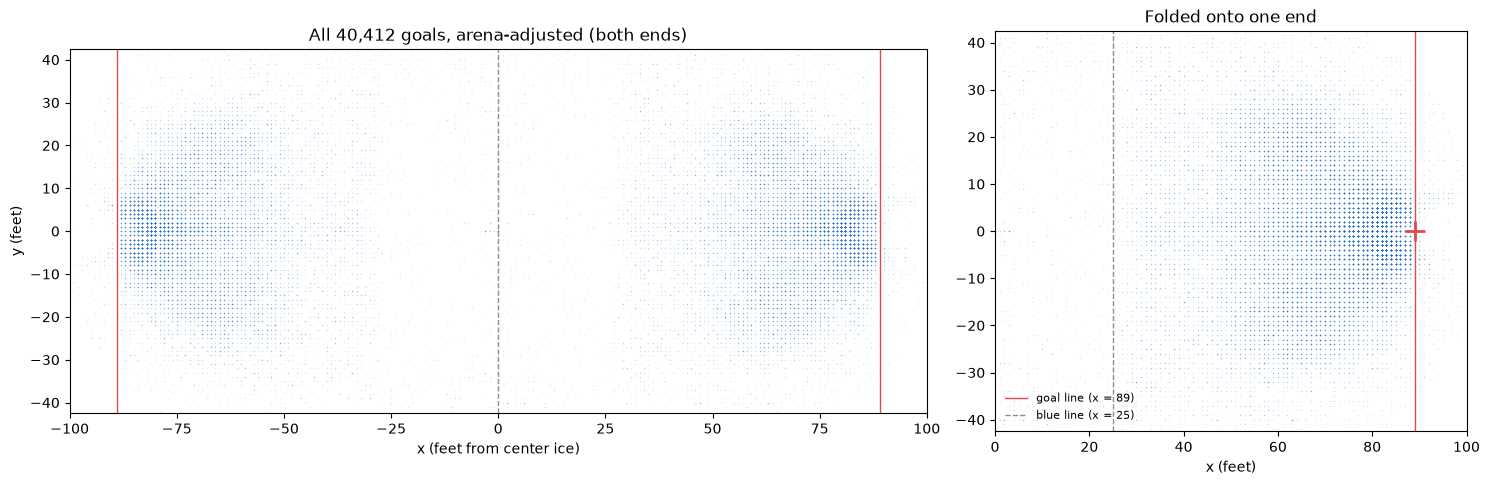

Goals within 20 feet of the net (folded): 52%


In [6]:
def fold(x, y):
    """Put every shot on the right end of the rink: x = |x|, and y flips with it."""
    side = np.sign(x).replace(0, 1)
    return x.abs(), y * side

fx_all, fy_all = fold(shots["arenaAdjustedXCord"], shots["arenaAdjustedYCord"])
both = (fy_all != 0) & (shots["yCordAdjusted"] != 0)
agree = (np.sign(fy_all[both]) == np.sign(shots.loc[both, "yCordAdjusted"])).mean()
print(f"Folded y has the same side as MoneyPuck's yCordAdjusted for {agree:.1%} of shots (expect about 99.9%)")

goals = shots[shots["goal"] == 1]
gx, gy = goals["arenaAdjustedXCord"], goals["arenaAdjustedYCord"]
fx, fy = fold(gx, gy)

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2, 1.1]})
left.scatter(gx, gy, s=1, alpha=0.15, color="#2a78d6", linewidths=0)
for x in (-89, 89):
    left.axvline(x, color="#e34948", linewidth=1)
left.axvline(0, color="#8f8e88", linewidth=1, linestyle="--")
left.set(xlim=(-100, 100), ylim=(-42.5, 42.5), title=f"All {len(goals):,} goals, arena-adjusted (both ends)",
         xlabel="x (feet from center ice)", ylabel="y (feet)")

right.scatter(fx, fy, s=1, alpha=0.15, color="#2a78d6", linewidths=0)
right.axvline(89, color="#e34948", linewidth=1, label="goal line (x = 89)")
right.axvline(25, color="#8f8e88", linewidth=1, linestyle="--", label="blue line (x = 25)")
right.plot([89], [0], marker="+", color="#e34948", markersize=14, markeredgewidth=2)
right.set(xlim=(0, 100), ylim=(-42.5, 42.5), title="Folded onto one end", xlabel="x (feet)")
right.legend(loc="lower left", fontsize=8, frameon=False)
for ax in (left, right):
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print(f"Goals within 20 feet of the net (folded): {(np.hypot(89 - fx, fy) <= 20).mean():.0%}")